## CONTINUAÇÃO DO PROJETO: DATASET 

In [21]:
import pandas as pd

gym = pd.read_csv(r"C:\Users\User\Downloads\Dev\miniproject\fitbase-project\data\gym_members_exercise_tracking.csv")

# Análise inicial:Tamanho do dataset, se tem dados nulos, tipos das colunas!

print(gym.shape)
print(gym.isnull().sum())
print(gym.dtypes)

# Análise inicial: 

(973, 15)
Age                              0
Gender                           0
Weight (kg)                      0
Height (m)                       0
Max_BPM                          0
Avg_BPM                          0
Resting_BPM                      0
Session_Duration (hours)         0
Calories_Burned                  0
Workout_Type                     0
Fat_Percentage                   0
Water_Intake (liters)            0
Workout_Frequency (days/week)    0
Experience_Level                 0
BMI                              0
dtype: int64
Age                                int64
Gender                               str
Weight (kg)                      float64
Height (m)                       float64
Max_BPM                            int64
Avg_BPM                            int64
Resting_BPM                        int64
Session_Duration (hours)         float64
Calories_Burned                  float64
Workout_Type                         str
Fat_Percentage                   float64
W

In [22]:
calorias_por_treino = (
    
    gym.groupby("Workout_Type", as_index=False)["Calories_Burned"].mean()
    .sort_values("Calories_Burned", ascending=False)
)
calorias_por_treino

,Workout_Type,Calories_Burned
1,HIIT,925.805430
2,Strength,910.697674
3,Yoga,903.188285
0,Cardio,884.513725


C:\Users\User\AppData\Local\Temp\ipykernel_16548\3484054554.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


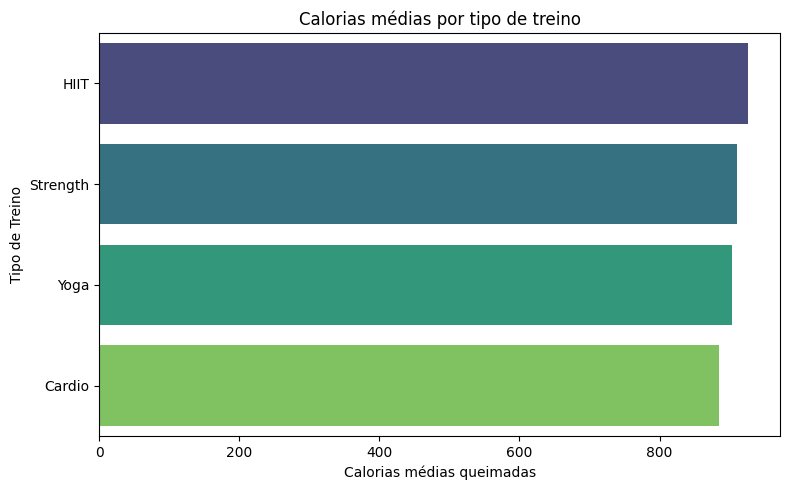

In [23]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
sns.barplot(
    data=calorias_por_treino,
    x="Calories_Burned",
    y="Workout_Type",
    orient="h",
    palette="viridis"
)
plt.title("Calorias médias por tipo de treino")
plt.xlabel("Calorias médias queimadas")
plt.ylabel("Tipo de Treino")
plt.tight_layout()
plt.show()


No dataset analisado, HIIT apresentou a maior média de calorias queimadas, seguido de Strength e Yoga. A diferença entre os tipos não é muito grande, o que indica que a duração e a intensidade da sessão também devem influenciar fortemente o gasto calórico.


In [24]:
#Verificar a Relação de Calorias queimadas com outros dados.

In [25]:
colunas = [
    "Calories_Burned",
    "Session_Duration (hours)",
    "Avg_BPM",
    "Workout_Frequency (days/week)"
    
]

corr = gym[colunas].corr()
corr

,Calories_Burned,Session_Duration (hours),Avg_BPM,Workout_Frequency (days/week)
Calories_Burned,1.000000,0.908140,0.339659,0.576150
Session_Duration (hours),0.908140,1.000000,0.016014,0.644140
Avg_BPM,0.339659,0.016014,1.000000,-0.010681
Workout_Frequency (days/week),0.576150,0.644140,-0.010681,1.000000


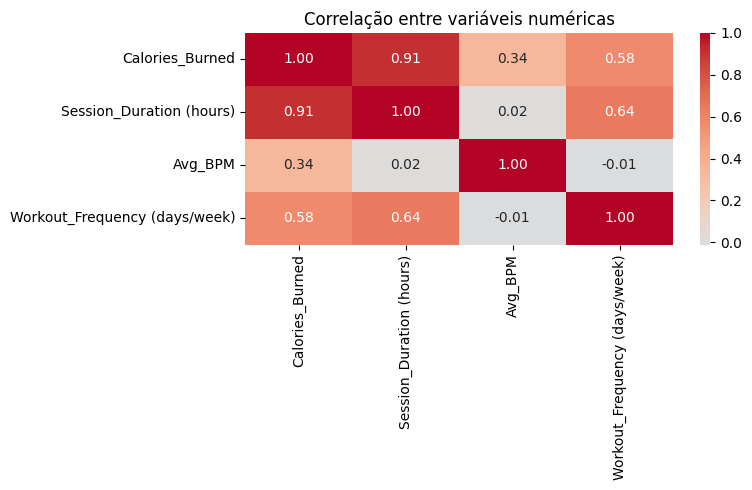

In [26]:
plt.figure(figsize=(8,5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0 )
plt.title("Correlação entre variáveis numéricas")
plt.tight_layout()
plt.show()

A variável com maior relação com calorias queimadas foi a duração da sessão (0.91), indicando que o tempo de treino é o principal fator associado ao gasto calórico. A frequência semanal também apresentou relação positiva moderada (0.58). Já a média de batimentos por minuto teve relação mais fraca (0.34), sugerindo menor poder explicativo isoladamente.

In [27]:
calorias_por_gender = (
gym.groupby("Gender", as_index=False)["Calories_Burned"].mean()
.sort_values("Calories_Burned", ascending=False)

)
calorias_por_gender

,Gender,Calories_Burned
1,Male,944.455969
0,Female,862.248918


In [30]:

calorias_por_treino = (
    
    gym.groupby("Workout_Type", as_index=False)["Calories_Burned"].mean()
    .sort_values("Calories_Burned", ascending=False)
)
calorias_por_treino

,Workout_Type,Calories_Burned
1,HIIT,925.805430
2,Strength,910.697674
3,Yoga,903.188285
0,Cardio,884.513725


In [29]:
calorias_por_exp = (
    
    gym.groupby("Experience_Level", as_index=False)["Calories_Burned"].mean()
    .sort_values("Calories_Burned", ascending=False)
    
)
calorias_por_exp

,Experience_Level,Calories_Burned
2,3,1265.340314
1,2,901.918719
0,1,726.375000


C:\Users\User\AppData\Local\Temp\ipykernel_16548\3983772687.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\User\AppData\Local\Temp\ipykernel_16548\3983772687.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\User\AppData\Local\Temp\ipykernel_16548\3983772687.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


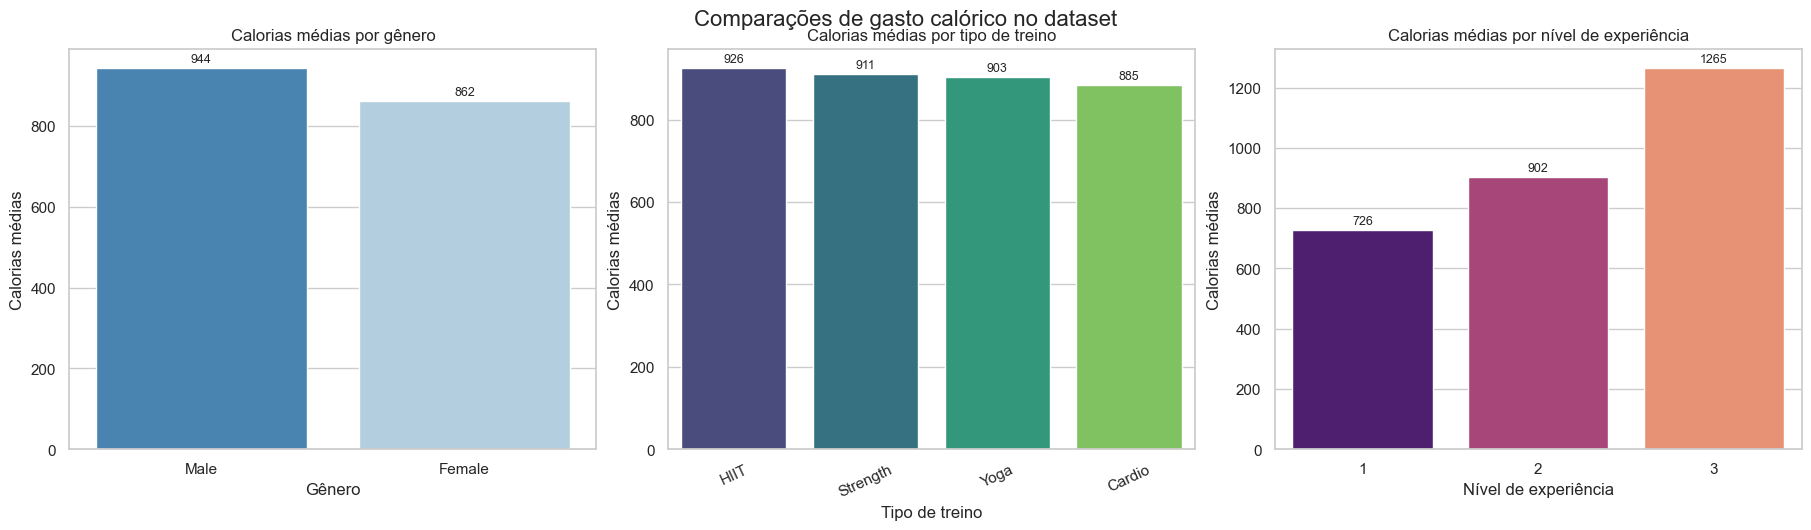

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 3, figsize=(18, 5), constrained_layout=True)

# 1) Gênero
sns.barplot(
    data=calorias_por_gender,
    x="Gender",
    y="Calories_Burned",
    ax=axes[0],
    palette="Blues_r"
)
axes[0].set_title("Calorias médias por gênero")
axes[0].set_xlabel("Gênero")
axes[0].set_ylabel("Calorias médias")

# 2) Tipo de treino
sns.barplot(
    data=calorias_por_treino,
    x="Workout_Type",
    y="Calories_Burned",
    ax=axes[1],
    palette="viridis"
)
axes[1].set_title("Calorias médias por tipo de treino")
axes[1].set_xlabel("Tipo de treino")
axes[1].set_ylabel("Calorias médias")
axes[1].tick_params(axis="x", rotation=25)

# 3) Nível de experiência
sns.barplot(
    data=calorias_por_exp,
    x="Experience_Level",
    y="Calories_Burned",
    ax=axes[2],
    palette="magma"
)
axes[2].set_title("Calorias médias por nível de experiência")
axes[2].set_xlabel("Nível de experiência")
axes[2].set_ylabel("Calorias médias")

# rótulos nas barras
for ax in axes:
    for container in ax.containers:
        ax.bar_label(container, fmt="%.0f", padding=2, fontsize=9)

plt.suptitle("Comparações de gasto calórico no dataset", fontsize=16, y=1.03)
plt.show()

## Conclusões do Dia 8

A base analisada está limpa, sem valores nulos, o que permitiu focar diretamente na exploração dos dados.

Os gráficos mostraram que:
- Homens apresentaram maior média de calorias queimadas do que mulheres.
- HIIT teve a maior média de calorias entre os tipos de treino.
- O nível de experiência 3 ficou muito acima dos demais níveis em calorias médias.

Além disso, a correlação mostrou que a duração da sessão é a variável mais fortemente associada ao gasto calórico, acima de BPM médio e frequência semanal.

**Limitação:** esses resultados mostram tendências do dataset e não relações de causa e efeito. Outras variáveis provavelmente também influenciam o gasto calórico.

O próximo passo será aprofundar a análise com novas comparações e, se possível, cruzar as variáveis com mais contexto.